<!-- <a href="https://colab.research.google.com/github/steflhermitte/EO-Notebooks/blob/master/PhysicalPrinciplesofEO/Radiative_Transfer_Modelling_wih_Prosail_py6S.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a> -->


[<img src="https://raw.githubusercontent.com/mbakker7/exploratory_computing_with_python/master/tudelft_logo.png" width="200" align='right'>](https://www.tudelft.nl/citg/over-faculteit/afdelingen/geoscience-remote-sensing/staff/scientific-staff/dr-stef-lhermitte)


# Radiative transfer modelling using prosail/6S  
*Created by Stef Lhermitte (s.lhermitte at tudelft.nl / [@steflhermitte](https://twitter.com/StefLhermitte) | www.earthmapps.io)*

[![Twitter](https://img.shields.io/twitter/url/https/twitter.com/cloudposse.svg?style=social&label=%20%40steflhermitte)](https://twitter.com/steflhermitte)

*Adapted (and cleaned up a bit) for PPESO by Paco Lopez-Dekker*



## General packages
Import general packages

In [3]:
import matplotlib.pyplot as plt
import numpy
import numpy as np
from mpl_toolkits.mplot3d import Axes3D
import pandas as pd

# Prosail
The [PROSAIL](https://jbferet.gitlab.io/prosail/index.html) model, a fusion of PROSPECT (leaf reflectance and transmittance) and SAIL (plant canopy reflectance), has been used for the last thirty years to simulate the spectral and directional reflectance of plant canopies in the solar domain. It links the spectral dimension of the reflectance, which is mainly related to the biochemical content of the leaves, to the directional dimension, which is mainly related to the architecture of the canopy. PROSAIL has been widely used to develop new methods to retrieve biophysical properties of vegetation and to prepare new space missions. 

In [4]:
# Load PROSPECT+SAIL Radiative transfer mode package
import prosail

Once `prosail` is imported, we can run a radiative transfer simulation the surface reflectance would at the bottom of atmosphere (i.e., just above the canopy) by setting the canopy properties. `prosail` takes a set of arguments:

Argument | explanation
--- | ---
n: float | Leaf layers
cab: float | leaf chlorophyll concentration
car: float | leaf carotenoid concentration
cbrown: float | senescent pigment
cw: float | equivalent leaf water
cm: float | leaf dry matter
lai: float | leaf area index
lidfa: float | a parameter for leaf angle distribution. If ``typliedf``=2, average leaf inclination angle.
tts: float | Solar zenith angle
tto: float | Sensor zenith angle
psi: float | Relative sensor-solar azimuth angle ( saa - vaa )
ant: float | leaf anthocyanin concentration (default set to 0)
alpha: float | The alpha angle (in degrees) used in the surface scattering calculations. By default it's set to 40 degrees.
prospect_version: str | Which PROSPECT version to use. We have "5" and "D"
typelidf: int, optional | The type of leaf angle distribution function to use. By default, is set to 2.
lidfb: float, optional | b parameter for leaf angle distribution. If ``typelidf``=2, ignored factor: str, optional
rsoil0: float, optional | The soil reflectance spectrum
rsoil: float, optional | Soil scalar 1 (brightness)
psoil: float, optional | Soil scalar 2 (moisture)
soil_spectrum1: 2101-element array |  First component of the soil spectrum
soil_spectrum2: 2101-element array | Second component of the soil spectrum


You can find a background on the `prosail` model settings on [doi:10.1016/j.rse.2008.01.026](https://www.sciencedirect.com/science/article/pii/S0034425709000765):

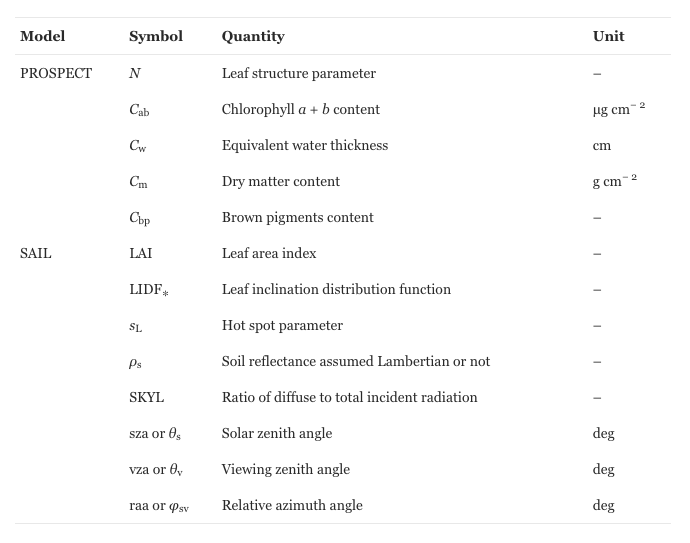

Prosail can return different reflectances:

Setting | meaning
--- | ---
SDR | directional reflectance factor (default)
BHR |  bi-hemispherical r. f.
DHR |  Directional-Hemispherical r. f. (directional illumination)
HDR | Hemispherical-Directional r. f. (directional view)
ALL | All of them
ALLALL | All of the terms calculated by SAIL, including the above

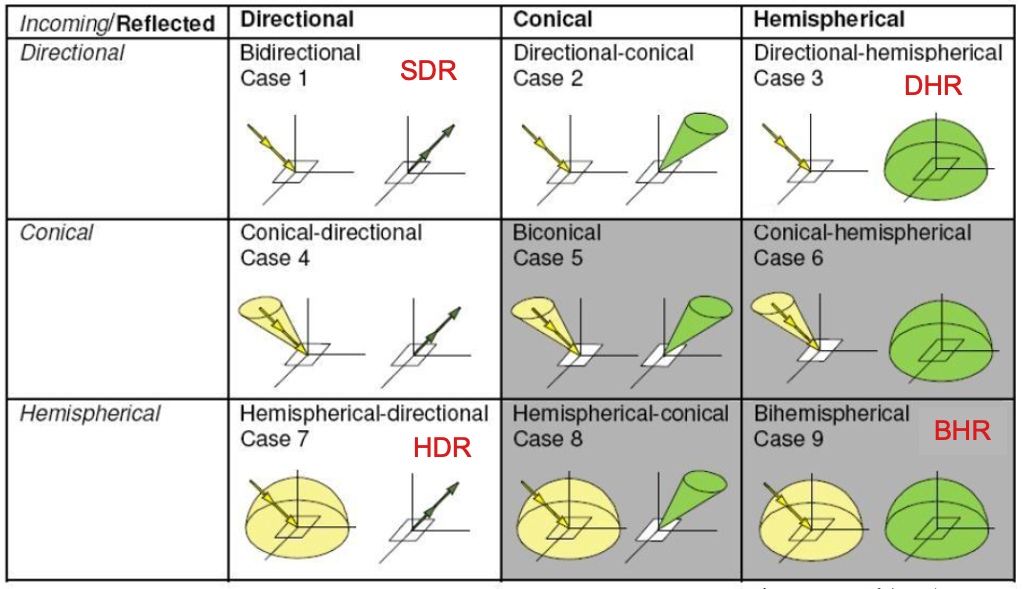

The soil model is a fairly simple linear mixture model, where two default spectra are mixed and then a brightness term added:

`rho_soil = rsoil*(psoil*soil_spectrum1+(1-psoil)*soil_spectrum2)`

The idea is that one of the spectra is a dry soil and the other a wet soil, so soil moisture is then controlled by psoil. rsoil is just a brightness scaling term.

With these settings we can run the prosail model and asses the input of the soil leaf canopy features

Text(0, 0.5, 'Reflectance []')

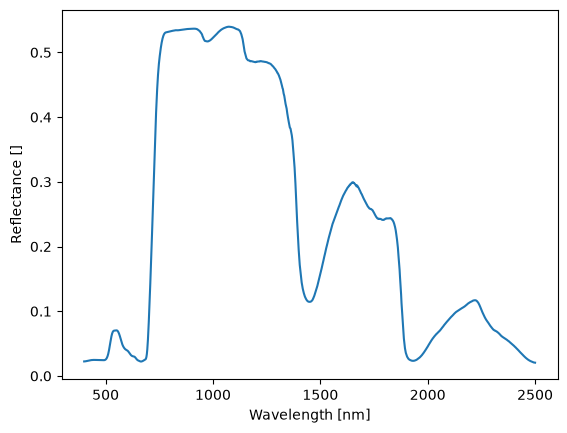

In [5]:
# Run the prosail model
rr = prosail.run_prosail(n=1.5, cab=40, car=8.0, cbrown=0.0, cw=0.01, cm=0.009, lai=3.00, lidfa=0.35, 
                         hspot=0.01, # hotspot parameter
                         tts=30, tto=10, psi=0, # observation geometry
                         rsoil=1.0, psoil=1.0, # soil description
                         factor="SDR")
wls_prosail = np.arange(400, 2501) # In nanometer
plt.plot(wls_prosail, rr)
plt.xlabel("Wavelength [nm]")
plt.ylabel("Reflectance []")

## Dependence on observation geometry

Let us consider the Sentine-2 case, whose orbit results in (ascending) acquisitons at 10:30 local time. Let us assume that the Sentinel-2 looks straight down (`tto=0`). The solar zenit angle will change over time. The solar zenit angle will change during the year, being large in the winter (i.e. low elevation) and small in the summer.
Do we expect the azimuth angle to be relevant?

In [6]:
# elevations: the Sun elevation angles to test, in degrees above the horizon.
elevations = np.linspace(1, 89, 10)
# rr_vs_el: table where the results are stored ("reflectance vs elevation").
rr_vs_el = np.zeros((10, rr.size))
# Run PROSAIL once for each Sun elevation; elind is the row number (0 to 9).
for elind in range(10):
    r_ = prosail.run_prosail(n=1.5, cab=40, car=8.0, cbrown=0.0, cw=0.01, cm=0.009, lai=1, lidfa=0.35, 
                         hspot=0.5, # hotspot parameter
                         tts=90 - elevations[elind], tto=0, psi=0, # observation geometry
                         rsoil=0.5, psoil=1, # soil description
                         factor="SDR") 
# Save this spectrum in row elind of the table
    rr_vs_el[elind] = r_

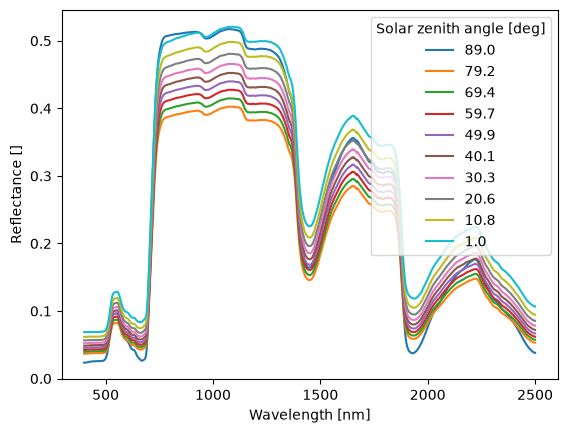

In [7]:
plt.figure()
wls = np.arange(rr.size)
for elind in range(10):
    plt.plot(wls_prosail,rr_vs_el[elind], label=("%2.1f" % (90 - elevations[elind])))
plt.legend()
plt.xlabel("Wavelength [nm]")
plt.ylabel("Reflectance []")
plt.legend(title="Solar zenith angle [deg]")

The bigger the azimuth sensor angle, the bigger the effect. Sentinel-2 views up to about 10–12° from straight down at the edges of its image strip, so in practice the azimuth has a small effect (around 0.01–0.02 reflectance). In this exercise the Sun zenith angle (the seasons) has the much bigger effect, if the sensor and the parcel we are observing had a horiyontal angle in between them, then the ayimuth angle could create high changes.

For example, we can compare the differences in Leaf Area Index (LAI):

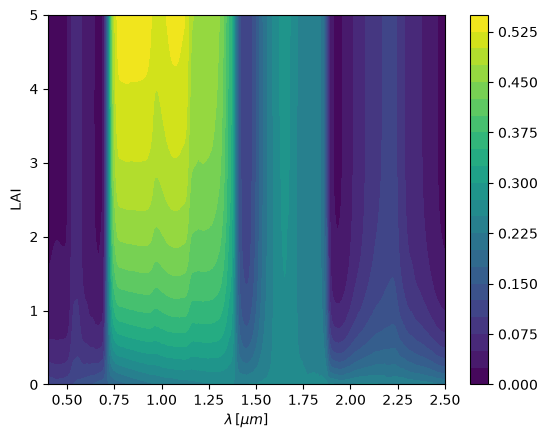

In [8]:
nlai = 40
LAIs = np.linspace(0, 5, nlai)

rr_vs_lai = np.zeros((nlai, rr.size))
for laiind in range(nlai):
    r_ = prosail.run_prosail(n=1.5, cab=40, car=8.0, cbrown=0.0, cw=0.01, cm=0.009, lai=LAIs[laiind], lidfa=0.35, 
                             hspot=0.01, # hotspot parameter
                             tts=45, tto=0, psi=0, # observation geometry
                             rsoil=0.5, psoil=1, # soil description
                             factor="SDR") 
    rr_vs_lai[laiind] = r_

plt.contourf(wls_prosail/1000, LAIs, rr_vs_lai, 20)
plt.xlabel("$\lambda\, [\mu m]$")
plt.ylabel("LAI")
plt.colorbar()



In [9]:
?prosail.run_prosail

Signature:
prosail.run_prosail(
    n,
    cab,
    car,
    cbrown,
    cw,
    cm,
    lai,
    lidfa,
    hspot,
    tts,
    tto,
    psi,
    ant=0.0,
    alpha=40.0,
    prospect_version='5',
    typelidf=2,
    lidfb=0.0,
    factor='SDR',
    rsoil0=None,
    rsoil=None,
    psoil=None,
    soil_spectrum1=None,
    soil_spectrum2=None,
)
Docstring:
Run the PROSPECT_5B and SAILh radiative transfer models. The soil
model is a linear mixture model, where two spectra are combined together as

     rho_soil = rsoil*(psoil*soil_spectrum1+(1-psoil)*soil_spectrum2)
By default, ``soil_spectrum1`` is a dry soil, and ``soil_spectrum2`` is a
wet soil, so in that case, ``psoil`` is a surface soil moisture parameter.
``rsoil`` is a  soil brightness term. You can provide one or the two
soil spectra if you want.  The soil spectra must be defined
between 400 and 2500 nm with 1nm spacing.

Parameters
----------
n: float
    Leaf layers
cab: float
    leaf chlorophyll concentration
car: float
   

# Impact of canopy properties on bottom of the atmosphere (BOA) reflectance

### Q1.
Fixing the LAI, study the relation between leaf chlorophyl content and the spectral
reflectance in the VNIR (0.4 𝜇𝑚 to 2.5 𝜇𝑚). Which of the Sentinel-2 MSI bands is most
sensitive to chlorophyl content? 

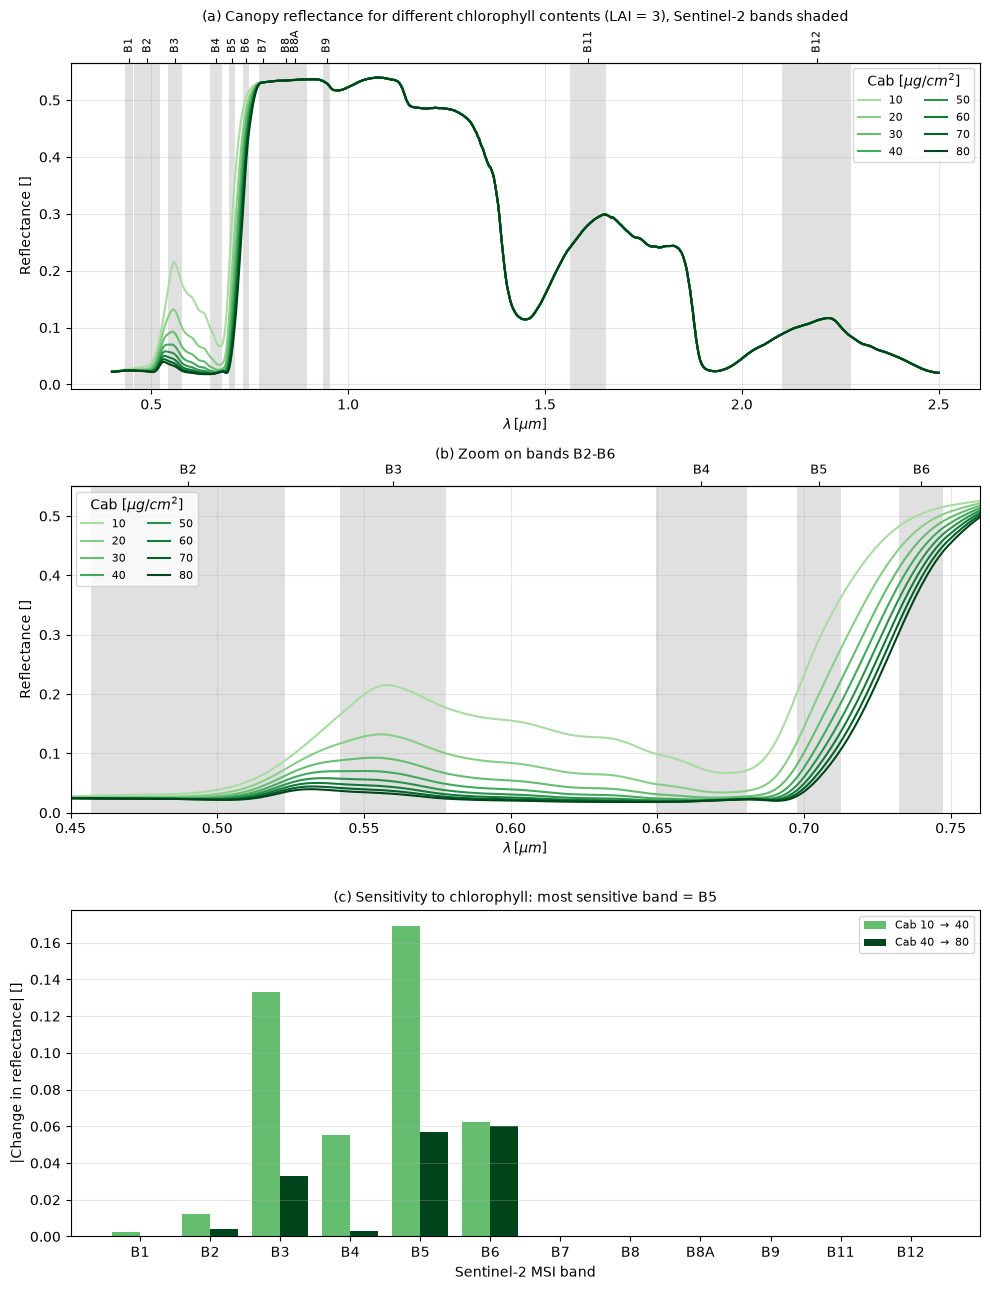

In [10]:
# Q1: how does leaf chlorophyll content (Cab) change the canopy reflectance,
# and which Sentinel-2 MSI band is most sensitive to it?

# ---- 1. Simulate canopy spectra for different chlorophyll contents ----
cabs = np.arange(10, 90, 10)          # Cab values to test: 10, 20, ..., 80 ug/cm2
wls_prosail = np.arange(400, 2501)    # PROSAIL wavelengths: 400-2500 nm, 1 nm steps

# rr_vs_cab: table of results, one row per Cab value, one column per wavelength
rr_vs_cab = np.zeros((cabs.size, wls_prosail.size))
for cabind in range(cabs.size):
    # Same canopy and geometry as the first PROSAIL run of the notebook;
    # only cab changes. LAI is fixed to 3.
    rr_vs_cab[cabind] = prosail.run_prosail(n=1.5, cab=cabs[cabind], car=8.0, cbrown=0.0, cw=0.01, cm=0.009,
                                            lai=3.00, lidfa=0.35,
                                            hspot=0.01,             # hotspot parameter
                                            tts=30, tto=10, psi=0,  # observation geometry
                                            rsoil=1.0, psoil=1.0,   # soil description
                                            factor="SDR")

# ---- 2. Sentinel-2 MSI bands: central wavelength and bandwidth in nm (Sentinel-2A) ----
# B10 (1375 nm, cirrus) is left out: it only sees the atmosphere, not the ground.
s2_bands = {"B1": (443, 21), "B2": (490, 66), "B3": (560, 36), "B4": (665, 31),
            "B5": (705, 15), "B6": (740, 15), "B7": (783, 20), "B8": (842, 106),
            "B8A": (865, 21), "B9": (945, 20), "B11": (1610, 91), "B12": (2190, 175)}
band_names = list(s2_bands)
band_centers = np.array([s2_bands[b][0] for b in band_names])

# Reflectance seen by each band = average of the spectrum over the band width
rr_bands = np.zeros((cabs.size, len(band_names)))
for j, b in enumerate(band_names):
    centre, width = s2_bands[b]
    inband = (wls_prosail >= centre - width / 2) & (wls_prosail <= centre + width / 2)
    rr_bands[:, j] = rr_vs_cab[:, inband].mean(axis=1)

# Sensitivity = how much the band reflectance changes when Cab changes
i10, i40, i80 = 0, list(cabs).index(40), cabs.size - 1
sens_low = np.abs(rr_bands[i40] - rr_bands[i10])    # change from Cab 10 to 40
sens_high = np.abs(rr_bands[i80] - rr_bands[i40])   # change from Cab 40 to 80
sens_total = np.abs(rr_bands[i80] - rr_bands[i10])  # change from Cab 10 to 80
most = band_names[np.argmax(sens_total)]

# ---- 3. Plots ----
colors = plt.cm.Greens(np.linspace(0.35, 1, cabs.size))  # light green = low Cab, dark green = high Cab
fig, axes = plt.subplots(3, 1, figsize=(10, 13))

# (a) Full spectra, one line per Cab, with the Sentinel-2 bands shaded
ax = axes[0]
for b in band_names:
    centre, width = s2_bands[b]
    ax.axvspan((centre - width / 2) / 1000, (centre + width / 2) / 1000, color="0.88", lw=0)
for cabind in range(cabs.size):
    ax.plot(wls_prosail / 1000, rr_vs_cab[cabind], color=colors[cabind], lw=1.5, label=f"{cabs[cabind]}")
top = ax.secondary_xaxis("top")                # Sentinel-2 band names on the top axis
top.set_xticks(band_centers / 1000)
top.set_xticklabels(band_names, rotation=90, fontsize=8)
ax.set_xlabel(r"$\lambda\,[\mu m]$")
ax.set_ylabel("Reflectance []")
ax.set_title("(a) Canopy reflectance for different chlorophyll contents (LAI = 3), Sentinel-2 bands shaded",
             fontsize=10, pad=30)
ax.legend(title=r"Cab [$\mu g/cm^2$]", ncol=2, fontsize=8)
ax.grid(alpha=0.3)

# (b) Zoom on the B2-B6 region (visible and red edge), where chlorophyll acts
ax = axes[1]
zoom_bands = ["B2", "B3", "B4", "B5", "B6"]
for b in zoom_bands:
    centre, width = s2_bands[b]
    ax.axvspan((centre - width / 2) / 1000, (centre + width / 2) / 1000, color="0.88", lw=0)
for cabind in range(cabs.size):
    ax.plot(wls_prosail / 1000, rr_vs_cab[cabind], color=colors[cabind], lw=1.5, label=f"{cabs[cabind]}")
top = ax.secondary_xaxis("top")
top.set_xticks([s2_bands[b][0] / 1000 for b in zoom_bands])
top.set_xticklabels(zoom_bands, fontsize=9)
ax.set_xlim(0.45, 0.76)
ax.set_ylim(0, 0.55)
ax.set_xlabel(r"$\lambda\,[\mu m]$")
ax.set_ylabel("Reflectance []")
ax.set_title("(b) Zoom on bands B2-B6", fontsize=10, pad=20)
ax.legend(title=r"Cab [$\mu g/cm^2$]", ncol=2, fontsize=8, loc="upper left")
ax.grid(alpha=0.3)

# (c) Sensitivity of each band: change in reflectance at low and at high Cab
ax = axes[2]
x = np.arange(len(band_names))
ax.bar(x - 0.2, sens_low, width=0.4, color=colors[2], label=r"Cab 10 $\rightarrow$ 40")
ax.bar(x + 0.2, sens_high, width=0.4, color=colors[-1], label=r"Cab 40 $\rightarrow$ 80")
ax.set_xticks(x)
ax.set_xticklabels(band_names)
ax.set_xlabel("Sentinel-2 MSI band")
ax.set_ylabel("|Change in reflectance| []")
ax.set_title(f"(c) Sensitivity to chlorophyll: most sensitive band = {most}", fontsize=10)
ax.legend(fontsize=8)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### Analysis:

- B5 band is the most sensitive, its reflectance changes by 0.226 between Cab 10 and 80, the largest of any band. Followed by B3 with reflectance change of 0.166. So from 0.4 𝜇𝑚 to 0.75 𝜇𝑚 spectrum the higher the Cab, the lower the reflectance. Chlorophyll absorbs light at these wavelengths. 
- More chlorophyll absorbs more light, so less is reflected. For the rest of the bands, (B7, B8, B8A, B9, B11, B12): no change, because chlorophyll doesn't absorb there.

### Q2.

Fixing the chlorophyl content to a reasonable (typical?) value, 40, as all of the notebook uses it. study now the relation
between LAI and the spectral reflectance

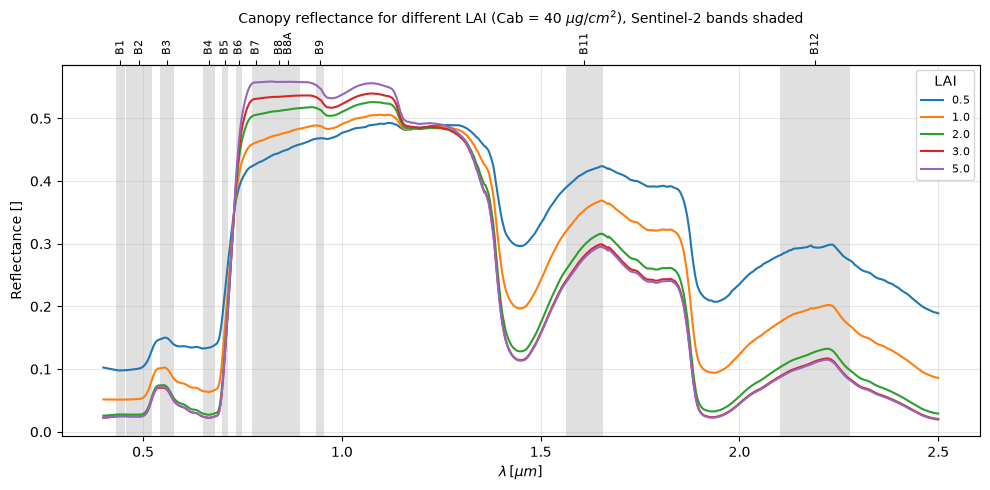

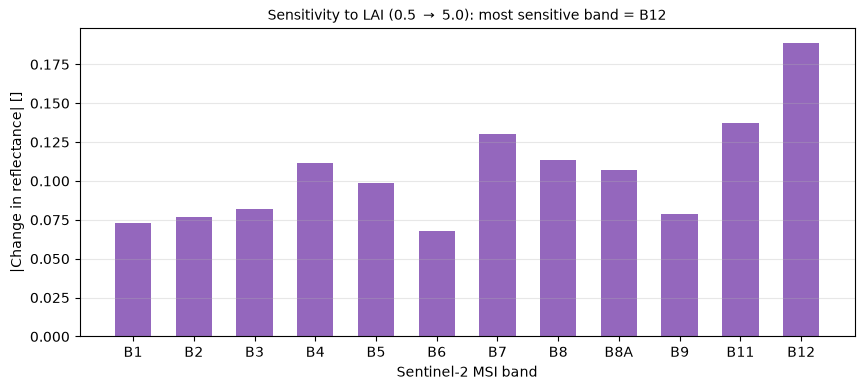

In [11]:
# Q2: how does the leaf area index (LAI) change the canopy reflectance,
# with the leaf chlorophyll content fixed to a typical value (Cab = 40 ug/cm2)?
# Same logic as Q1: simulate spectra, average them over the Sentinel-2 bands, plot.
# s2_bands, band_names and band_centers come from the Q1 cell.

# ---- 1. Simulate canopy spectra for different LAI values ----
lais = np.array([0.5, 1, 2, 3, 5])    # LAI values to test [m2 leaf / m2 ground]
wls_prosail = np.arange(400, 2501)    # PROSAIL wavelengths: 400-2500 nm, 1 nm steps

# rr_vs_lai2: table of results, one row per LAI value, one column per wavelength
rr_vs_lai2 = np.zeros((lais.size, wls_prosail.size))
for laiind in range(lais.size):
    # Same canopy and geometry as Q1; only lai changes. Cab is fixed to 40.
    rr_vs_lai2[laiind] = prosail.run_prosail(n=1.5, cab=40, car=8.0, cbrown=0.0, cw=0.01, cm=0.009,
                                             lai=lais[laiind], lidfa=0.35,
                                             hspot=0.01,             # hotspot parameter
                                             tts=30, tto=10, psi=0,  # observation geometry
                                             rsoil=1.0, psoil=1.0,   # soil description
                                             factor="SDR")

# ---- 2. Reflectance seen by each Sentinel-2 band = average over the band width ----
rr_bands_lai = np.zeros((lais.size, len(band_names)))
for j, b in enumerate(band_names):
    centre, width = s2_bands[b]
    inband = (wls_prosail >= centre - width / 2) & (wls_prosail <= centre + width / 2)
    rr_bands_lai[:, j] = rr_vs_lai2[:, inband].mean(axis=1)

# Sensitivity = how much the band reflectance changes from the lowest to the highest LAI
sens_lai = np.abs(rr_bands_lai[-1] - rr_bands_lai[0])
most_lai = band_names[np.argmax(sens_lai)]

# ---- 3. Plot: all LAI spectra overlaid in one graph, Sentinel-2 bands shaded ----
colors = plt.cm.tab10(np.arange(lais.size))   # a clearly different colour for each LAI
fig, ax = plt.subplots(figsize=(10, 5))
for b in band_names:
    centre, width = s2_bands[b]
    ax.axvspan((centre - width / 2) / 1000, (centre + width / 2) / 1000, color="0.88", lw=0)
for laiind in range(lais.size):
    ax.plot(wls_prosail / 1000, rr_vs_lai2[laiind], color=colors[laiind], lw=1.5, label=f"{lais[laiind]}")
top = ax.secondary_xaxis("top")                # Sentinel-2 band names on the top axis
top.set_xticks(band_centers / 1000)
top.set_xticklabels(band_names, rotation=90, fontsize=8)
ax.set_xlabel(r"$\lambda\,[\mu m]$")
ax.set_ylabel("Reflectance []")
ax.set_title(r"Canopy reflectance for different LAI (Cab = 40 $\mu g/cm^2$), Sentinel-2 bands shaded",
             fontsize=10, pad=30)
ax.legend(title="LAI", fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ---- 4. Sensitivity of each band to LAI (same idea as Q1 panel c) ----
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(band_names))
ax.bar(x, sens_lai, width=0.6, color=colors[-1])
ax.set_xticks(x)
ax.set_xticklabels(band_names)
ax.set_xlabel("Sentinel-2 MSI band")
ax.set_ylabel("|Change in reflectance| []")
ax.set_title(rf"Sensitivity to LAI ({lais[0]} $\rightarrow$ {lais[-1]}): most sensitive band = {most_lai}",
             fontsize=10)
ax.grid(axis="y", alpha=0.3)
plt.show()

### Analysis

- Visible bands (B1–B5) and SWIR bands (B11, B12) go down as LAI goes up. Why?
The more leaves the more cover of bright soil, and the leaves absorb these wavelengths by specifically absorbing chlorophyll in the visible bands, and leaf water in the SWIR bands.
- Near-infrared bands (B6–B9) go up as LAI goes up. Leaves reflect strongly in the near-infrared, and each extra leaf layer adds to that. So the more vegetation, more reflectance.


### Q3.

Something highly important is water stress (shortage of water). Changing the leaf water
content, explore which wavelengths (and which MSI band) is most sensitive to water-
stress

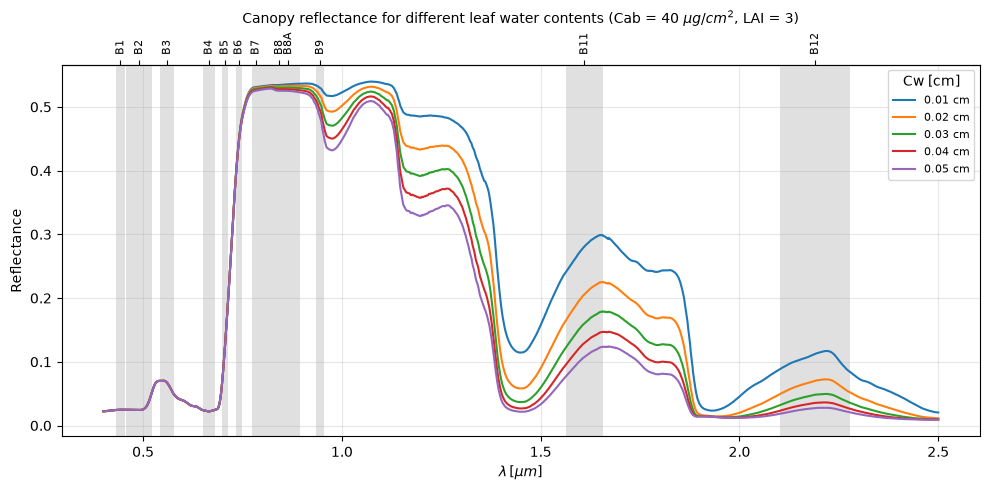

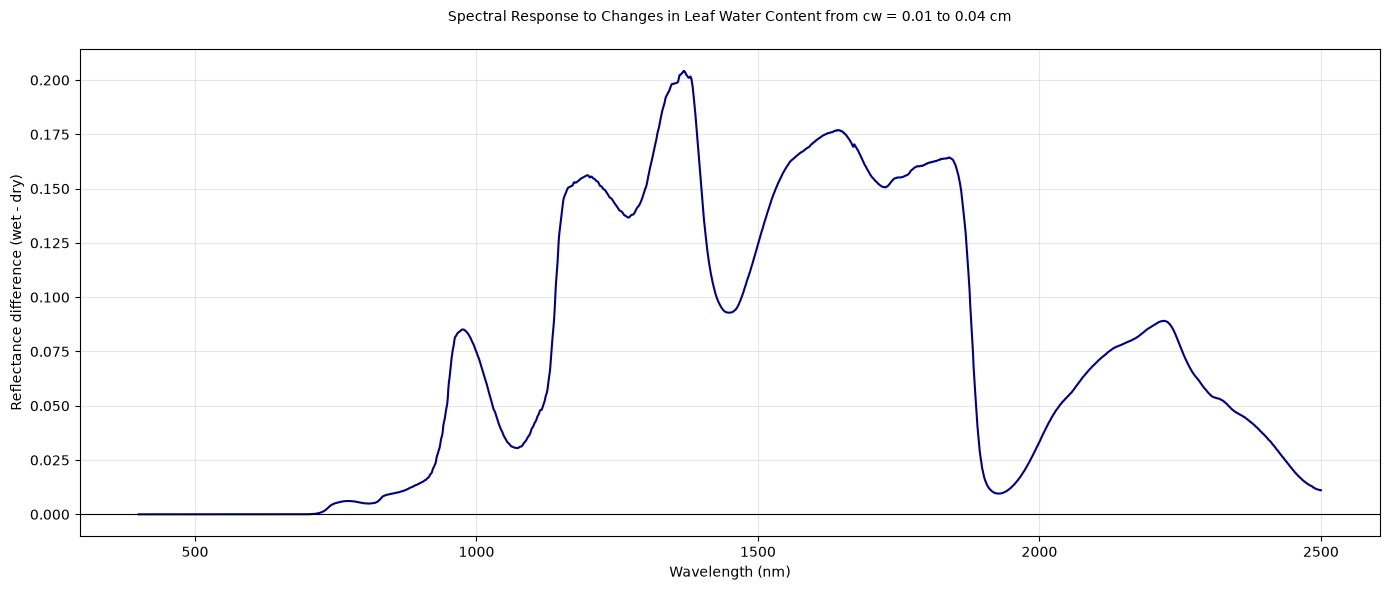


MOST SENSITIVE WAVELENGTH OVERALL:
1368 nm
Sensitivity: 5.1049 per cm

MOST SENSITIVE WAVELENGTH WITHIN SENTINEL-2 MSI:
Wavelength: 1643 nm
MSI band: B11 SWIR 1
Sensitivity: 4.4241 per cm

MSI BAND SENSITIVITY RANKING:
       MSI Band  Mean sensitivity
     B11 SWIR 1           4.30654
     B12 SWIR 2           1.97642
B9 Water Vapour           1.20571
 B8A Narrow NIR           0.26131
         B8 NIR           0.21739
  B7 Red Edge 3           0.14668
  B6 Red Edge 2           0.09575
  B5 Red Edge 1           0.00261
       B3 Green           0.00008
         B4 Red           0.00002
        B2 Blue           0.00001


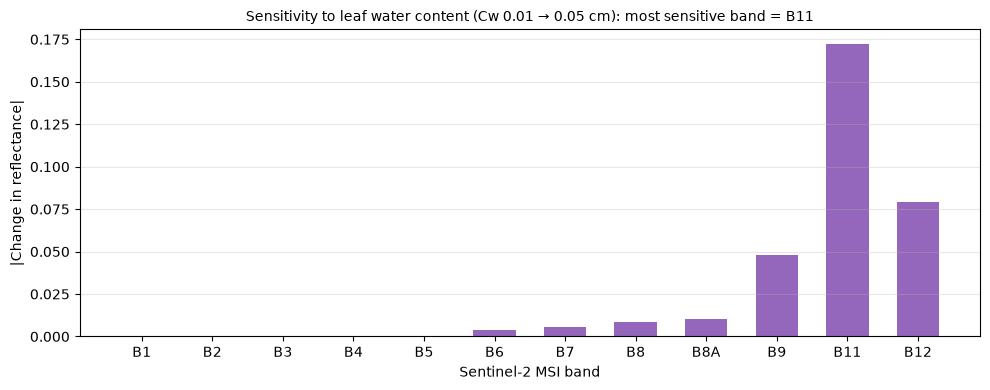

In [17]:

# Q3: How does leaf water content (Cw) change canopy reflectance,
# and which Sentinel-2 MSI band is most sensitive to water stress?

# s2_bands, band_names and band_centers come from the Q1 cell.

# ------------------------------------------------
# 1. Simulate canopy spectra for different leaf water contents
# ------------------------------------------------

cws = np.array([0.01, 0.02, 0.03, 0.04, 0.05])  # Cw values [cm]
wls_prosail = np.arange(400, 2501)               # Wavelengths [nm]

# rr_vs_cw: one row per Cw value, one column per wavelength
rr_vs_cw = np.zeros((cws.size, wls_prosail.size))

for cwind in range(cws.size):

    # Same canopy and geometry as Q1 and Q2; only Cw changes
    rr_vs_cw[cwind] = prosail.run_prosail(
        n=1.5,
        cab=40,
        car=8.0,
        cbrown=0.0,
        cw=cws[cwind],
        cm=0.009,
        lai=3.00,
        lidfa=0.35,
        hspot=0.01,
        tts=30,
        tto=10,
        psi=0,
        rsoil=1.0,
        psoil=1.0,
        factor="SDR"
    )


# ------------------------------------------------
# 2. Average reflectance over Sentinel-2 bands
# ------------------------------------------------

rr_bands_cw = np.zeros((cws.size, len(band_names)))

for j, b in enumerate(band_names):
    centre, width = s2_bands[b]

    inband = (
        (wls_prosail >= centre - width / 2) &
        (wls_prosail <= centre + width / 2)
    )

    rr_bands_cw[:, j] = rr_vs_cw[:, inband].mean(axis=1)


# Sensitivity between the lowest and highest Cw
sens_cw = np.abs(rr_bands_cw[-1] - rr_bands_cw[0])

most_cw = band_names[np.argmax(sens_cw)]


# ------------------------------------------------
# 3. Plot canopy spectra for different Cw values
# ------------------------------------------------

colors = plt.cm.tab10(np.arange(cws.size))

fig, ax = plt.subplots(figsize=(10, 5))

# Shade Sentinel-2 band wavelength ranges
for b in band_names:
    centre, width = s2_bands[b]

    ax.axvspan(
        (centre - width / 2) / 1000,
        (centre + width / 2) / 1000,
        color="0.88",
        lw=0
    )

# Plot spectra
for cwind in range(cws.size):
    ax.plot(
        wls_prosail / 1000,
        rr_vs_cw[cwind],
        color=colors[cwind],
        lw=1.5,
        label=f"{cws[cwind]:.2f} cm"
    )

# Sentinel-2 band labels on top axis
top = ax.secondary_xaxis("top")
top.set_xticks(band_centers / 1000)
top.set_xticklabels(band_names, rotation=90, fontsize=8)

ax.set_xlabel(r"$\lambda\,[\mu m]$")
ax.set_ylabel("Reflectance")
ax.set_title(
    r"Canopy reflectance for different leaf water contents "
    r"(Cab = 40 $\mu g/cm^2$, LAI = 3)",
    fontsize=10,
    pad=30
)

ax.legend(title="Cw [cm]", fontsize=8)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()



# ------------------------------------------------
# 4. Calculate spectral reflectance difference
#    between dry and wet leaf conditions
# ------------------------------------------------

cw_dry = cws[0]       # 0.01 cm
cw_wet = cws[-1]      # 0.05 cm

# First row = dry canopy; last row = wet canopy
rr1 = rr_vs_cw[0]
rr2 = rr_vs_cw[-1]

# Reflectance difference: wet minus dry
delta_R = rr1 - rr2

# Absolute reflectance difference
abs_difference = np.abs(delta_R)

# Sensitivity per unit change in leaf water content
sensitivity = abs_difference / abs(cw_wet - cw_dry)


# ------------------------------------------------
# 5. Plot spectral reflectance difference
# ------------------------------------------------

plt.figure(figsize=(14, 6))

plt.plot(wls_prosail, delta_R, color="darkblue")

plt.axhline(0, color="black", linewidth=0.8)

plt.xlabel("Wavelength (nm)")
plt.ylabel("Reflectance difference (wet - dry)")
plt.title("Spectral Response to Changes in Leaf Water Content from cw = 0.01 to 0.04 cm", fontsize=10, pad=20)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ------------------------------------------------
# 6. Most sensitive wavelength overall
# ------------------------------------------------

max_idx = np.argmax(sensitivity)

max_wavelength = wls_prosail[max_idx]
max_sensitivity = sensitivity[max_idx]

print("\nMOST SENSITIVE WAVELENGTH OVERALL:")
print(f"{max_wavelength} nm")
print(f"Sensitivity: {max_sensitivity:.4f} per cm")


# ------------------------------------------------
# 7. Most sensitive wavelength within Sentinel-2 MSI
# ------------------------------------------------

# Sentinel-2 MSI approximate wavelength ranges [nm]
msi_bands = {
    "B2 Blue": (458, 523),
    "B3 Green": (543, 578),
    "B4 Red": (650, 680),
    "B5 Red Edge 1": (698, 713),
    "B6 Red Edge 2": (733, 748),
    "B7 Red Edge 3": (773, 793),
    "B8 NIR": (785, 900),
    "B8A Narrow NIR": (855, 875),
    "B9 Water Vapour": (935, 955),
    "B11 SWIR 1": (1565, 1655),
    "B12 SWIR 2": (2100, 2280)
}

# Find all wavelengths covered by MSI bands
msi_mask = np.zeros(len(wls_prosail), dtype=bool)

for low, high in msi_bands.values():
    msi_mask |= (
        (wls_prosail >= low) &
        (wls_prosail <= high)
    )

# Find maximum sensitivity within MSI wavelengths
msi_indices = np.where(msi_mask)[0]

msi_max_idx = msi_indices[
    np.argmax(sensitivity[msi_indices])
]

msi_max_wavelength = wls_prosail[msi_max_idx]
msi_max_sensitivity = sensitivity[msi_max_idx]

# Identify corresponding MSI band
most_sensitive_band = None

for band, (low, high) in msi_bands.items():
    if low <= msi_max_wavelength <= high:
        most_sensitive_band = band
        break

print("\nMOST SENSITIVE WAVELENGTH WITHIN SENTINEL-2 MSI:")
print(f"Wavelength: {msi_max_wavelength} nm")
print(f"MSI band: {most_sensitive_band}")
print(f"Sensitivity: {msi_max_sensitivity:.4f} per cm")


# ------------------------------------------------
# 8. Calculate mean sensitivity for each MSI band
# ------------------------------------------------

band_results = []

for band, (low, high) in msi_bands.items():

    mask = (
        (wls_prosail >= low) &
        (wls_prosail <= high)
    )

    mean_sensitivity = np.mean(sensitivity[mask])

    band_results.append({
        "MSI Band": band,
        "Mean sensitivity": mean_sensitivity
    })

# Create and rank results table
band_df = pd.DataFrame(band_results)

band_df = band_df.sort_values(
    by="Mean sensitivity",
    ascending=False
)

print("\nMSI BAND SENSITIVITY RANKING:")
print(band_df.round(5).to_string(index=False))

# ------------------------------------------------
# 9. Sensitivity of each Sentinel-2 band
# ------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 4))

x = np.arange(len(band_names))

ax.bar(x, sens_cw, width=0.6, color=colors[-1])

ax.set_xticks(x)
ax.set_xticklabels(band_names)

ax.set_xlabel("Sentinel-2 MSI band")
ax.set_ylabel("|Change in reflectance|")
ax.set_title(
    f"Sensitivity to leaf water content "
    f"(Cw {cws[0]} → {cws[-1]} cm): "
    f"most sensitive band = {most_cw}",
    fontsize=10
)

ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()



### Analysis
Starting from near-infrared to mid-infrared, specifically the SWIR wavelengths we can see a high sensitivity to water stress.  
Being B11 the most sensitive band to water stress. The relationship we observe is the more water means lower reflectance, so water stressed or drier leaf show higher reflectance particularly at B11.

### Q4

As discussed during the lecture, the NDVI is a very popular index used to monitor
vegetation. Explore the relation (e.g. can we find a regression curve?) between NDVI (for
example using the B8 and B4 MSI bands) and LAI. What are the other main parametes
impacting the NDVI

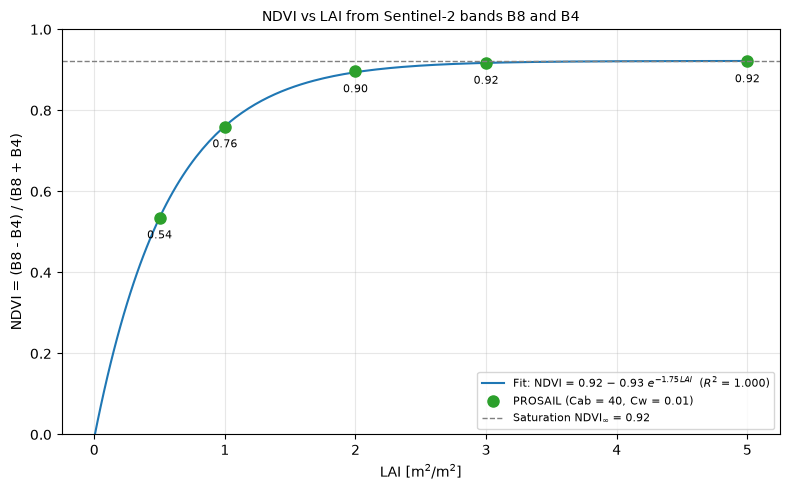

LAI = 0.5   NDVI = 0.536
LAI = 1.0   NDVI = 0.760
LAI = 2.0   NDVI = 0.896
LAI = 3.0   NDVI = 0.917
LAI = 5.0   NDVI = 0.921


In [ ]:
# Q4: relation between NDVI (from Sentinel-2 bands B8 and B4) and LAI.
# Uses the band reflectances of the 5 LAI values simulated in Q2 (lais, rr_bands_lai),
# so run the Q1 and Q2 cells first.
from scipy.optimize import curve_fit

# ---- 1. NDVI for each LAI ----
b4 = rr_bands_lai[:, band_names.index("B4")]   # red
b8 = rr_bands_lai[:, band_names.index("B8")]   # near-infrared
ndvi = (b8 - b4) / (b8 + b4)

# ---- 2. Regression curve: exponential saturation (Baret & Guyot, 1991) ----
# NDVI = NDVI_inf - (NDVI_inf - NDVI_soil) * exp(-K * LAI)
def ndvi_model(lai, ndvi_inf, ndvi_soil, k):
    return ndvi_inf - (ndvi_inf - ndvi_soil) * np.exp(-k * lai)

popt, _ = curve_fit(ndvi_model, lais, ndvi, p0=[0.9, 0.2, 1.0])
ndvi_inf, ndvi_soil, k = popt
r2 = 1 - np.sum((ndvi - ndvi_model(lais, *popt))**2) / np.sum((ndvi - ndvi.mean())**2)

# ---- 3. Plot ----
lai_fine = np.linspace(0, lais.max(), 200)
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(lai_fine, ndvi_model(lai_fine, *popt), color="tab:blue", lw=1.5,
        label=rf"Fit: NDVI = {ndvi_inf:.2f} $-$ {ndvi_inf - ndvi_soil:.2f} $e^{{-{k:.2f}\,LAI}}$  ($R^2$ = {r2:.3f})")
ax.plot(lais, ndvi, "o", color="tab:green", ms=8, label="PROSAIL (Cab = 40, Cw = 0.01)")
for l, n in zip(lais, ndvi):
    ax.annotate(f"{n:.2f}", (l, n), textcoords="offset points", xytext=(0, -15), ha="center", fontsize=8)
ax.axhline(ndvi_inf, color="0.5", ls="--", lw=1, label=rf"Saturation NDVI$_\infty$ = {ndvi_inf:.2f}")
ax.set_xlabel(r"LAI [m$^2$/m$^2$]")
ax.set_ylabel("NDVI = (B8 - B4) / (B8 + B4)")
ax.set_title("NDVI vs LAI from Sentinel-2 bands B8 and B4", fontsize=10)
ax.set_ylim(0, 1)
ax.legend(fontsize=8, loc="lower right")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

for l, n in zip(lais, ndvi):
    print(f"LAI = {l:<4}  NDVI = {n:.3f}")

### Analysis

So we see an exponential regression curve can fit the relationship between LAI and NDVI using B8 and B4. Additionally we observe that NDVI saturates. It rises steeply up to about LAI 2, then levels off at about 0.92. Between LAI 3 and LAI 5 it barely changes, so NDVI can't tell those two canopies apart. 

Other main parameters that impact the NDVI are: 
- Soil background (brightness and moisture). 
- Leaf chlorophyll content (Cab). 
- Canopy structure: 
- Sun and viewing geometry (solar zenith, view zenith, relative azimuth). 
- Leaf structure (N) and dry matter (Cm) so water content (Cw). 
- The atmosphere (next up).

# Py6S

[Py6S](https://py6s.readthedocs.io/en/latest/) is a interface to the Second Simulation of the Satellite Signal in the Solar Spectrum ([6S](https://en.wikipedia.org/wiki/6S_(radiative_transfer_code))) atmospheric Radiative Transfer Model through the Python programming language. It allows you to run 6S simulations. 6S is an advanced radiative transfer code designed to simulate the reflection of solar radiation by a coupled atmosphere-surface system for a wide range of atmospheric, spectral and geometrical conditions. It belongs to the group of procedures called Atmospheric correction for the process of removing the effects of the atmosphere on the reflectance values of images taken by satellite or airborne sensors. 

In [ ]:
# Load the Py6S module
import Py6S as p6s
p6s.SixS.test()

6S wrapper script by Robin Wilson
Using 6S located at C:\Users\Sergio\tudelft-conda\envs\py6s-env\Library\bin\sixs.exe
Running 6S using a set of test parameters
6sV version: 1.1
The results are:
Expected result: 619.158000
Actual result: 619.158000
#### Results agree, Py6S is working correctly


0

6S simulates the radiative transfer components across the whole atmosphere for different wavelengths. The SixS class is at the heart of Py6S. It has methods and attributes that allow you to set 6S parameters, run 6S and then view the outputs.

Py6S sets every 6S parameter to a sensible default, so the simplest possible code just uses the default values. As a nice introduction, we’re going to plot one of the 6S outputs across the whole Visible-NIR wavelength range:

Running for many wavelengths - this may take a long time


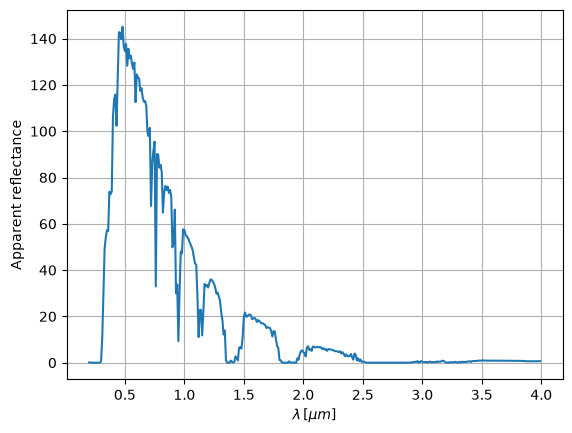

In [ ]:
# Create a SixS object called s (used as the standard name by convention)
s = p6s.SixS()
# Run the 6S simulation defined by this SixS object across the
# whole VIS range
wavelengths, results = p6s.SixSHelpers.Wavelengths.run_whole_range(s, output_name="pixel_radiance")
# Plot these results, with the y axis label set to "Pixel Radiance"
# We could use the helper function
# p6s.SixSHelpers.Wavelengths.plot_wavelengths(wavelengths, results, "Pixel Radiance")
# But I (PLD) prefer to have full control of my plots
plt.figure()
plt.plot(wavelengths, results)
plt.xlabel(r"$\lambda\,[\mu m]$")
plt.ylabel("Apparent reflectance")
plt.grid()

## 6S inputs

We can subsequently change the input parameters to modify the atmosphere or background etc:

In [ ]:
s.atmos_profile = p6s.AtmosProfile.PredefinedType(p6s.AtmosProfile.Tropical)
s.wavelength = p6s.Wavelength(0.357)
s.run()
print(s.outputs.pixel_radiance)

59.344


you can see here that we have changed the atmospheric profile to a pre-defined profile called ‘Tropical’, and changed the wavelength that we are using for the simulation to 0.357 micrometres. You can also see that here we’re accessing the outputs directly, rather than running it over a specific wavelength range and plotting it. 

In [ ]:
s.outputs.direct_solar_irradiance

208.329

Lets have a look at the input parameters that we can change, summarised in the table below:

SixS | Parameter |	Description	Possible values
--- | --- | ---
atmos_profile	| Atmospheric profile (pressure, water vapour, ozone etc)	| Any outputs from AtmosProfile
aero_profile | Aerosol profile (types, distributions etc)	| Any outputs from AeroProfile
ground_reflectance |	Ground reflectance (Homogeneity, BRDF etc.)	| Any outputs from GroundReflectance
geometry	| Viewing/Illumination geometry (manual or satellite-specific) |	A Geometry* class, for example Geometry.User
aot550	| Aerosol Optical Thickness at 550nm	| Floating point number
visibility	| Visibility in km	| Floating point number
altitude	| Altitudes of the sensor and target	| An instance of the Altitudes class
atmos_corr	| Atmospheric correction settings (yes/no, reflectances)	| Any outputs from AtmosCorr


For example we can change the atmospheric profiles and specify some specific satellite wavelengths.

In [ ]:
s.atmos_profile = p6s.AtmosProfile.UserWaterAndOzone(3.6, 0.9) # Set the atmosphere profile to be based on 3.6cm of water and 0.9cm-atm of ozone
s.wavelength = p6s.Wavelength(p6s.PredefinedWavelengths.LANDSAT_TM_B3) # Set the wavelength to be that of the Landsat TM Band 3 - includes response function
# Set the viewing/solar geometry
s.geometry.view_z = 45 # Set the viewing zenith angle
s.geometry.solar_z = 45 # Set the solar zenith angle
# Set the altitudes of target and satellite
s.altitudes.set_target_sea_level() # Put the target at sea
s.altitudes.set_sensor_satellite_level() # Put the sensor at satellite level
s.run()
print(s.outputs.pixel_radiance)

37.392


Or we can set the `GroundReflectance` to the reflectance we model with `prosail`:

Running for many wavelengths - this may take a long time


<Figure size 640x480 with 0 Axes>

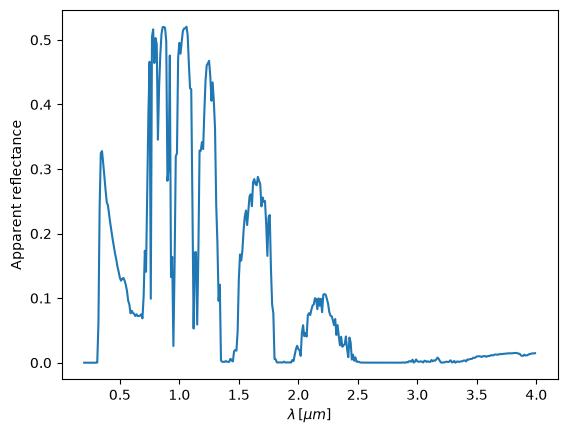

<Figure size 640x480 with 0 Axes>

In [ ]:
spectrum = np.transpose(np.vstack( (wls_prosail/1000.0, rr) ))
# Perform a 6S simulation with the simulated GroundReflectance
s.ground_reflectance = p6s.GroundReflectance.HomogeneousLambertian(spectrum)
# Get the output
wavelengths, results = p6s.SixSHelpers.Wavelengths.run_whole_range(s, output_name="apparent_reflectance")
# Plot these results, with the y axis label set to "Pixel Radiance"
plt.figure()
plt.plot(wavelengths, results)
plt.xlabel(r"$\lambda\,[\mu m]$")
plt.ylabel("Apparent reflectance")
plt.figure()

## 6S outputs
The outputs from the 6S model are available under the s.outputs attribute and you can explore the by typing `s.outputs.` and pressing `CTRL+SPACE`.

It is often necessary to run a simulation across a number of wavelengths - as it is very rare that we are only interested in a single wavelength. We saw an example of this above, when we used the `run_whole_range` method to run a simulation across the Visible-NIR wavelengths. We can do similar things for other wavelengths really easily. For example:

In [ ]:
# for the vnir range only
ws, res = p6s.SixSHelpers.Wavelengths.run_vnir(s, output_name="pixel_radiance")
# for the whole range, but at a coarser resolution, so that it's quicker
# wv, res = SixSHelpers.Wavelengths.run_whole_range(s, spacing=0.030, output_name='pixel_radiance')
# Run for the Landsat TM bands
# wv, res = SixSHelpers.Wavelengths.run_landsat_tm(s, output_name='pixel_radiance')
# Run for the Sentinel-2 bands
wv, res = p6s.SixSHelpers.Wavelengths.run_s2a_msi(s, output_name='pixel_radiance')

Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time


## Example: end-to-end
With all this info we can run a simulation where we compare the 6S Top of Atmosphere (TOA) at sensor reflectance with the prosail bottom of atmosphere reflectance and the output of Sentinel-2 only:

Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time


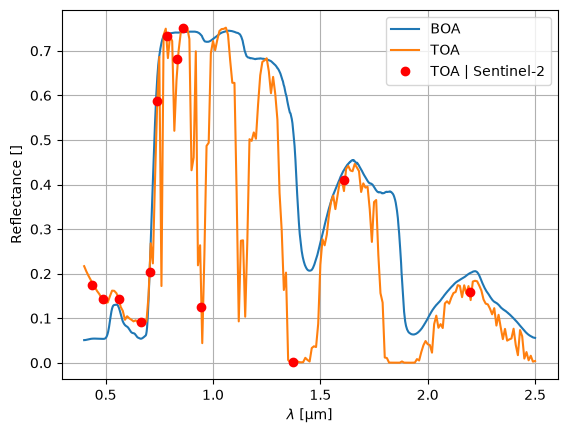

In [ ]:
# Run prosail
rr = prosail.run_prosail(n=1.5, cab=40, car=8.0, cbrown=0.0, cw=0.01, cm=0.009, lai=3.00, lidfa=0.35, hspot=0.01, tts=0, tto=0, psi=0, rsoil=1.0, psoil=1.0, factor="SDR") 
# Make a spectrum which combines the wavelengths with the reflectance
spectrum = np.transpose(np.vstack( (wls_prosail/1000.0, rr) ))
# Perform a 6S simulation with the simulated GroundReflectance
s = p6s.SixS()
# Set the ground reflectance
s.ground_reflectance = p6s.GroundReflectance.HomogeneousLambertian(spectrum)
# Set the altitudes
s.altitudes.set_target_sea_level()
s.altitudes.set_sensor_satellite_level()
s.atmos_profile = p6s.AtmosProfile.UserWaterAndOzone(3.6, 0.9)
# Get the output for TOA
# wv_vnir, R_vnir = p6s.SixSHelpers.Wavelengths.run_vnir(s, output_name="apparent_reflectance")
# Here 
wv_vnir, R_vnir = p6s.SixSHelpers.Wavelengths.run_wavelengths(s, wls_prosail[::10]/1000, output_name="apparent_reflectance")
# wv, res = SixSHelpers.Wavelengths.run_whole_range(s, spacing=0.050, output_name="apparent_reflectance") # If you want to speed up the calculation
# Get the output for TOA for Sentinel-2
wv_msi, R_msi = p6s.SixSHelpers.Wavelengths.run_s2a_msi(s, output_name="apparent_reflectance")
plt.plot(wls_prosail/1e3,rr, label="BOA")
plt.plot(wv_vnir,R_vnir,label="TOA")
plt.plot(wv_msi,R_msi,'ro',label="TOA | Sentinel-2")
plt.xlabel("$\lambda$ [µm]")
plt.ylabel("Reflectance []")
plt.grid()
plt.legend()

### Change atmospheric conditions:
The lines below will run the same simulation, but changing the vertically integrated water column to a lower value.

Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time


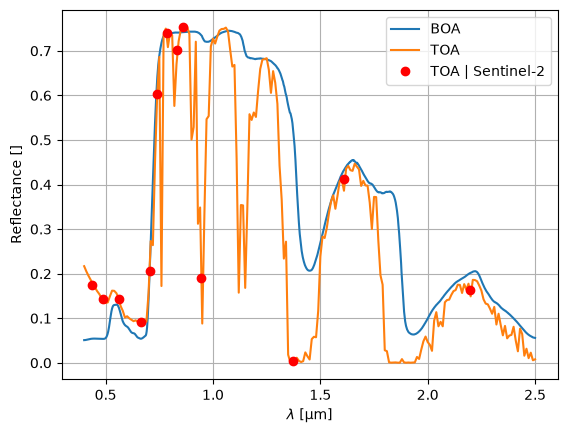

In [ ]:

s.atmos_profile = p6s.AtmosProfile.UserWaterAndOzone(2, 0.9) # Set the atmosphere profile to be based on 3.6cm of water and 0.9cm-atm of ozone
s.visibility = 1
# Set the altitudes
# s.altitudes.set_target_sea_level()
# s.altitudes.set_sensor_satellite_level()
# # Set ground reflectance
# s.ground_reflectance = GroundReflectance.HomogeneousLambertian(spectrum)
# Get the output for TOA
wv_vnir, R_vnir = p6s.SixSHelpers.Wavelengths.run_wavelengths(s, wls_prosail[::10]/1000, output_name="apparent_reflectance")
# Get the output for TOA for Sentinel-2
wv_msi, R_msi = p6s.SixSHelpers.Wavelengths.run_s2a_msi(s, output_name="apparent_reflectance")

# Plot
plt.plot(wls_prosail/1e3,rr, label="BOA")
plt.plot(wv_vnir,R_vnir,label="TOA")
plt.plot(wv_msi,R_msi,'ro',label="TOA | Sentinel-2")
plt.xlabel("$\lambda$ [µm]")
plt.ylabel("Reflectance []")
plt.grid()
plt.legend()

### Tweak observation geometry
Here we run the same again, but chaning the zenith angle of the sensor and the zenith angle of the Sun

Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time


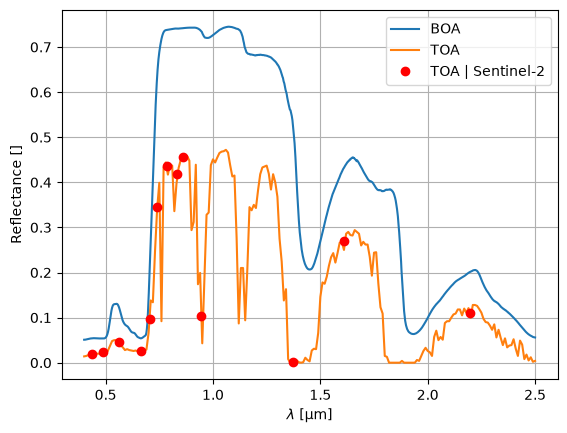

In [ ]:
s.atmos_profile = p6s.AtmosProfile.UserWaterAndOzone(2, 0.9) # Set the atmosphere profile to be based on 3.6cm of water and 0.9cm-atm of ozone
s.visibility = 1
s.geometry.view_z = 10
s.geometry.solar_z = 50
# Set the altitudes
# s.altitudes.set_target_sea_level()
# s.altitudes.set_sensor_satellite_level()
# # Set ground reflectance
# s.ground_reflectance = GroundReflectance.HomogeneousLambertian(spectrum)
# Get the output for TOA
wv_vnir, R_vnir = p6s.SixSHelpers.Wavelengths.run_wavelengths(s, wls_prosail[::10]/1000, output_name="pixel_reflectance")
# Get the output for TOA for Sentinel-2
wv_msi, R_msi = p6s.SixSHelpers.Wavelengths.run_s2a_msi(s, output_name="pixel_reflectance")

# Plot
plt.plot(wls_prosail/1e3,rr, label="BOA")
plt.plot(wv_vnir,R_vnir,label="TOA")
plt.plot(wv_msi,R_msi,'ro',label="TOA | Sentinel-2")
plt.xlabel("$\lambda$ [µm]")
plt.ylabel("Reflectance []")
plt.grid()
plt.legend()

### Impact of the atmosphere


#### 5. Difference between TOA and BOA reflectance

The difference between Bottom of Atmosphere (BOA) and Top of Atmosphere (TOA) reflectance is caused by the interaction of electromagnetic radiation with the atmosphere.

BOA reflectance represents the radiation reflected by the Earth's surface, while TOA reflectance represents the apparent reflectance measured by a satellite sensor after the radiation has travelled through the atmosphere.

There are three main atmospheric effects:
1. Rayleigh scattering: Atmospheric molecules scatter short wavelengths more strongly than longer wavelengths. This is particularly important in the blue part of the spectrum.
2. Aerosol scattering: Aerosols such as dust and small particles scatter incoming solar radiation and can increase the radiation reaching the sensor.
3. Atmospheric absorption: Gases such as water vapour and ozone absorb radiation at particular wavelengths, reducing the amount of radiation reaching the satellite.

The higher TOA reflectance at short wavelengths can be explained mainly by Rayleigh scattering. Scattered sunlight is redirected towards the sensor, adding atmospheric path radiance to the signal reflected by the surface.

#### 6. Impact of atmospheric water and ozone

In [20]:
import numpy as np
import matplotlib.pyplot as plt
import prosail
import Py6S as p6s

# Wavelengths used by PROSAIL (nm)
# If wls_prosail is already defined earlier in your notebook,
# keep using that existing variable.
wls_prosail = np.arange(400, 2501)

# Baseline atmospheric conditions
water_baseline = 2.0   # cm
ozone_baseline = 0.9   # cm-atm


def run_simulation(lai=3.0, water=water_baseline,
                   ozone=ozone_baseline):

    # 1. Run PROSAIL to calculate BOA reflectance
    rr = prosail.run_prosail(
        n=1.5, cab=40, car=8.0, cbrown=0.0,
        cw=0.01, cm=0.009, lai=lai, lidfa=0.35,
        hspot=0.01, tts=0, tto=0, psi=0,
        rsoil=1.0, psoil=1.0, factor="SDR"
    )

    # 2. Combine wavelengths and BOA reflectance
    spectrum = np.transpose(
        np.vstack((wls_prosail / 1000.0, rr))
    )

    # 3. Set up the 6S simulation
    s = p6s.SixS()
    s.ground_reflectance = (
        p6s.GroundReflectance.HomogeneousLambertian(spectrum)
    )

    # 4. Set altitudes and atmospheric conditions
    s.altitudes.set_target_sea_level()
    s.altitudes.set_sensor_satellite_level()
    s.atmos_profile = p6s.AtmosProfile.UserWaterAndOzone(
        water, ozone
    )

    # 5. Calculate TOA reflectance over the VNIR wavelengths
    wv_vnir, R_vnir = (
        p6s.SixSHelpers.Wavelengths.run_wavelengths(
            s,
            wls_prosail[::10] / 1000.0,
            output_name="apparent_reflectance"
        )
    )

    # 6. Calculate TOA reflectance for Sentinel-2 MSI
    wv_msi, R_msi = (
        p6s.SixSHelpers.Wavelengths.run_s2a_msi(
            s,
            output_name="apparent_reflectance"
        )
    )

    return rr, wv_vnir, R_vnir, wv_msi, R_msi

Vary water, keeping ozone fixed

Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time


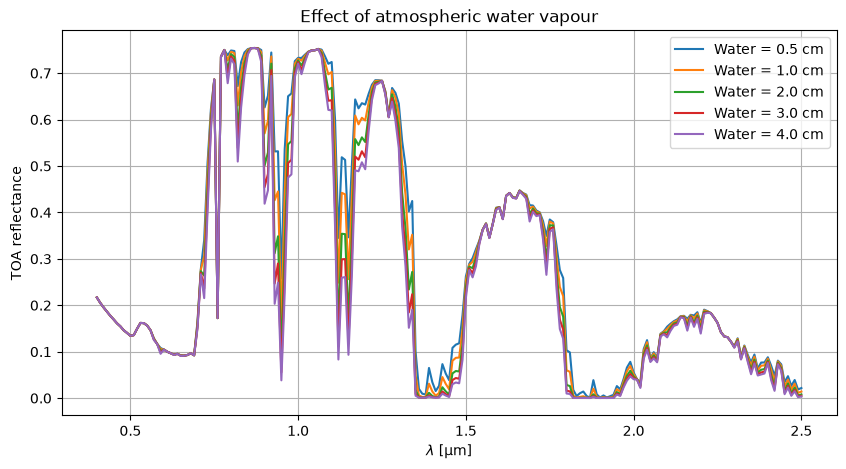

In [21]:
water_values = [0.5, 1.0, 2.0, 3.0, 4.0]

plt.figure(figsize=(10, 5))

for water in water_values:
    rr, wv_vnir, R_vnir, wv_msi, R_msi = run_simulation(
        water=water,
        ozone=ozone_baseline
    )

    plt.plot(wv_vnir, R_vnir, label=f"Water = {water} cm")

plt.xlabel(r"$\lambda$ [µm]")
plt.ylabel("TOA reflectance")
plt.title("Effect of atmospheric water vapour")
plt.grid()
plt.legend()
plt.show()

Quantify water-vapour sensitivity

Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time


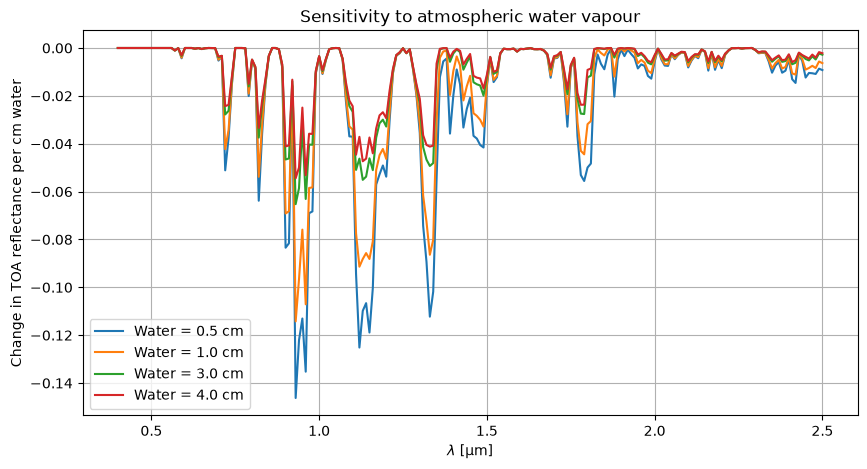

In [35]:
# Baseline TOA reflectance
rr, wv_vnir, R_baseline, wv_msi, R_msi = run_simulation(
    water=water_baseline,
    ozone=ozone_baseline
)

plt.figure(figsize=(10, 5))

for water in water_values:
    if water == water_baseline:
        continue

    rr, wv, R, _, _ = run_simulation(
        water=water,
        ozone=ozone_baseline
    )

    sensitivity = (
        (R - R_baseline) / (water - water_baseline)
    )

    plt.plot(
        wv,
        sensitivity,
        label=f"Water = {water} cm"
    )

plt.xlabel(r"$\lambda$ [µm]")
plt.ylabel("Change in TOA reflectance per cm water")
plt.title("Sensitivity to atmospheric water vapour")
plt.grid()
plt.legend()
plt.show()

Vary ozone, keeping water vapour fixed

Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time


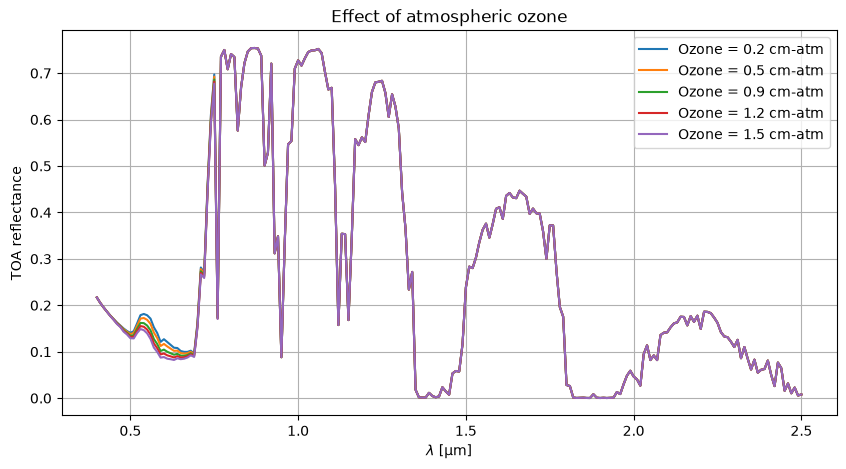

In [23]:
ozone_values = [0.2, 0.5, 0.9, 1.2, 1.5]

plt.figure(figsize=(10, 5))

for ozone in ozone_values:
    rr, wv_vnir, R_vnir, wv_msi, R_msi = run_simulation(
        water=water_baseline,
        ozone=ozone
    )

    plt.plot(wv_vnir, R_vnir, label=f"Ozone = {ozone} cm-atm")

plt.xlabel(r"$\lambda$ [µm]")
plt.ylabel("TOA reflectance")
plt.title("Effect of atmospheric ozone")
plt.grid()
plt.legend()
plt.show()

Compare the sensitivity of Sentinel-2 MSI bands to water vapour

Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time


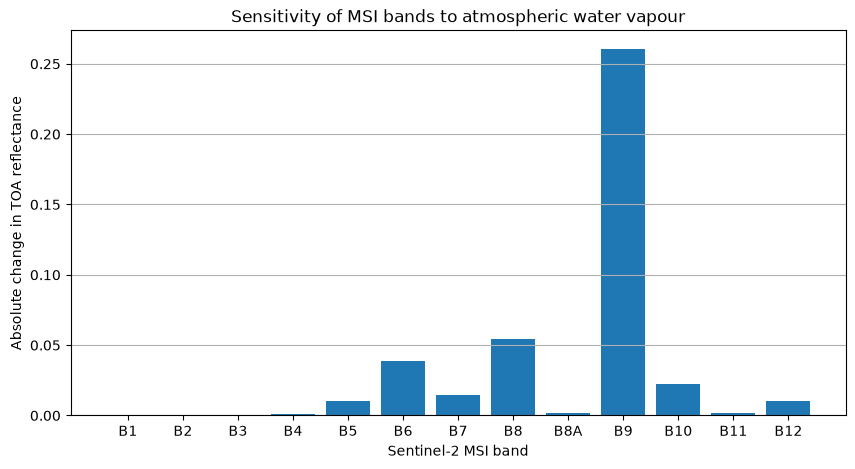

B1: 0.00000
B2: 0.00000
B3: 0.00038
B4: 0.00106
B5: 0.01059
B6: 0.03855
B7: 0.01479
B8: 0.05428
B8A: 0.00165
B9: 0.26065
B10: 0.02251
B11: 0.00181
B12: 0.01023


In [27]:
# Simulate low and high atmospheric water vapour
_, _, _, wv_msi_low, R_low = run_simulation(
    water=0.5, ozone=ozone_baseline
)

_, _, _, wv_msi_high, R_high = run_simulation(
    water=4.0, ozone=ozone_baseline
)

band_names = [
    "B1", "B2", "B3", "B4", "B5", "B6", "B7",
    "B8", "B8A", "B9", "B10", "B11", "B12"
]

# Absolute reflectance change for each band
sensitivity = np.abs(R_high - R_low)

plt.figure(figsize=(10, 5))
plt.bar(band_names, sensitivity)
plt.xlabel("Sentinel-2 MSI band")
plt.ylabel("Absolute change in TOA reflectance")
plt.title("Sensitivity of MSI bands to atmospheric water vapour")
plt.grid(axis="y")
plt.show()

# Print sensitivity values
for band, value in zip(band_names, sensitivity):
    print(f"{band}: {value:.5f}")

Analysis:

- Varying water vapor column: The simulated spectra show that increasing column water deepens and broadens the absorption troughs near 940 nm and 1130 nm, while the visible region stays essentially unchanged. As seen in the image, the "Water vapour" spectrum shows strong NIR absorption around 0.9–1.0 µm and 1.1–1.3 µm, with the 1.4 µm band saturated and sitting where incoming solar radiation is already low. Sensitivity is therefore concentrated in the 940 and 1130 nm features, with the NIR plateau mildly affected. Among MSI bands, B9 (945 nm) is most sensitive, B8A (865 nm) and B8 (842 nm) act as nearby windows.

- Varying ozone column: The simulated spectra show a smooth, broad decrease across the green–red region as ozone increases. As seen in the image, "Oxygen and Ozone" absorption spectrum shows ozone absorption concentrated in the UV plus a weak, broad feature around 0.5–0.7 µm (the Chappuis band), producing smooth attenuation near 600 nm with negligible NIR/SWIR effect. The MSI bands most affected are B3 (560 nm) and B4 (665 nm), with B2 (490 nm) on the wing. Unlike water vapor, the ozone effect is spectrally smooth and can be represented by a single multiplicative factor per band.

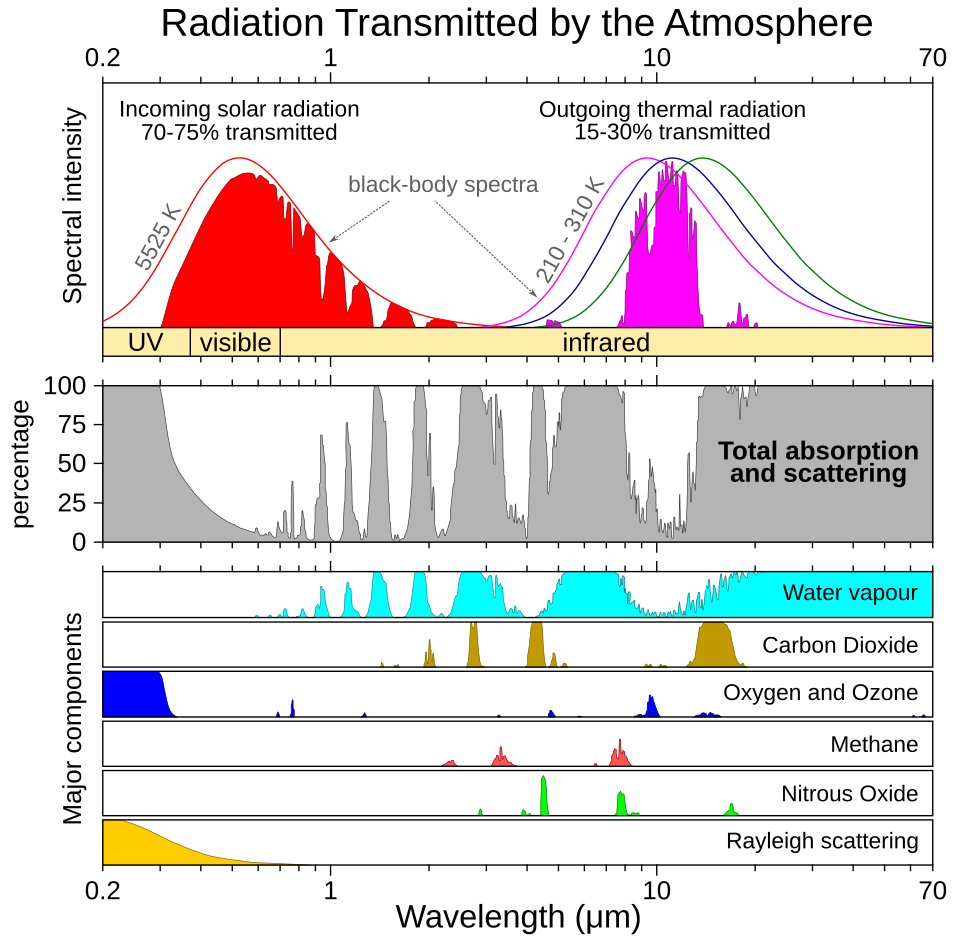

#### 7. Estimating atmospheric water vapour


a. Algorithm using Sentinel-2 MSI bands

The proposed algorithm uses the ratio between B9 and B8A:

$$
\text{Water vapour index}=\frac{R_{\mathrm{B9}}}{R_{\mathrm{B8A}}}
$$

B9 is sensitive to atmospheric water vapour absorption, while B8A is used as a reference because it is less affected by water vapour absorption.

Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time


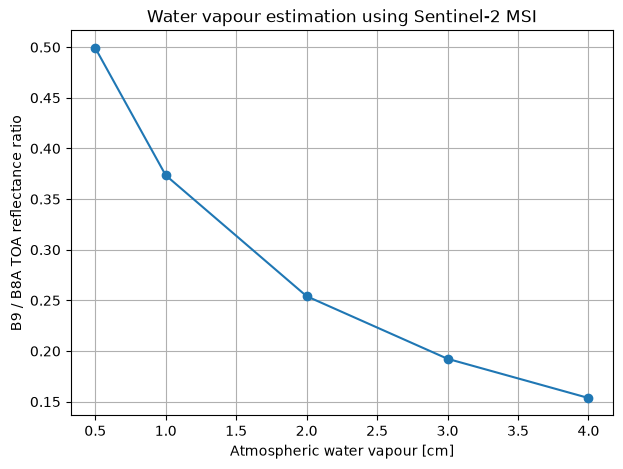

In [30]:

water_values = [0.5, 1.0, 2.0, 3.0, 4.0]

ratios_msi = []

for water in water_values:
    _, _, _, wv_msi, R_msi = run_simulation(
        water=water,
        ozone=ozone_baseline
    )

    # Convert wavelengths and reflectances to NumPy arrays
    wv_msi = np.asarray(wv_msi)
    R_msi = np.asarray(R_msi)

    # Find Sentinel-2 B8A and B9
    i_b8a = np.argmin(np.abs(wv_msi - 0.8595))
    i_b9 = np.argmin(np.abs(wv_msi - 0.94575))

    # Calculate reflectance ratio
    ratio = R_msi[i_b9] / R_msi[i_b8a]
    ratios_msi.append(ratio)

plt.figure(figsize=(7, 5))
plt.plot(water_values, ratios_msi, "o-")
plt.xlabel("Atmospheric water vapour [cm]")
plt.ylabel("B9 / B8A TOA reflectance ratio")
plt.title("Water vapour estimation using Sentinel-2 MSI")
plt.grid()
plt.show()


b. Algorithm using additional spectral bands

A sensor with additional narrow spectral bands could measure the water-vapour absorption feature more precisely.

We can use:
- 0.865 µm as the reference wavelength.
- 0.940 µm as the water-vapour absorption wavelength.

The algorithm is:

$$
\text{Water vapour index}=
\frac{R_{\mathrm{TOA}}(0.940)}
{R_{\mathrm{TOA}}(0.865)}
$$


Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time


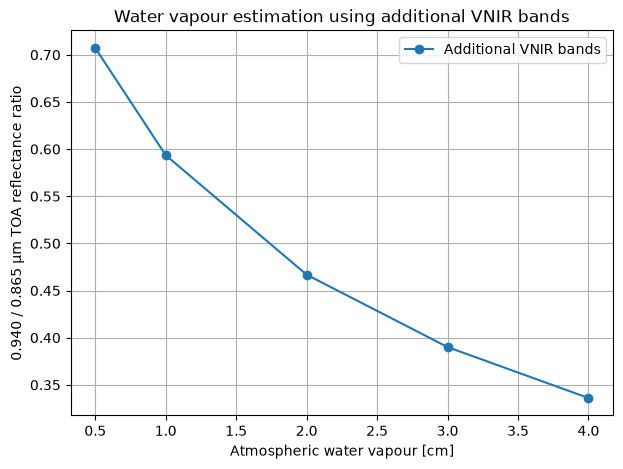

In [ ]:

# Water vapour values
water_values = [0.5, 1.0, 2.0, 3.0, 4.0]

ratios_vnir = []

# Define the two wavelengths in micrometres
selected_wavelengths = np.array([0.865, 0.940])

for water in water_values:

    # Run PROSAIL and 6S simulation
    rr, wv_vnir, R_vnir, _, _ = run_simulation(
        water=water,
        ozone=ozone_baseline
    )

    # Interpolate reflectance at the selected wavelengths
    R_selected = np.interp(
        selected_wavelengths,
        wv_vnir,
        R_vnir
    )

    # Calculate the reflectance ratio
    ratio = R_selected[1] / R_selected[0]
    ratios_vnir.append(ratio)

# Plot the relationship
plt.figure(figsize=(7, 5))
plt.plot(water_values, ratios_vnir, "o-", label="Additional VNIR bands")
plt.xlabel("Atmospheric water vapour [cm]")
plt.ylabel("0.940 / 0.865 µm TOA reflectance ratio")
plt.title("Water vapour estimation using additional VNIR bands")
plt.grid()
plt.legend()
plt.show()


Test robustness to changes in vegetation properties (LAI)

a. 

Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time


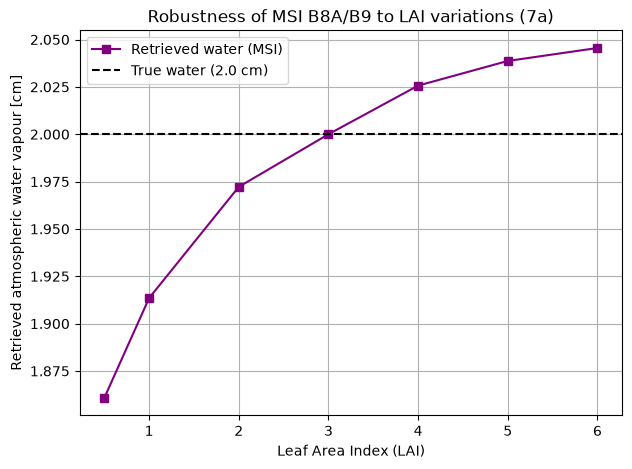

In [40]:

true_water = 2.0  # cm
lai_values = [0.5, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0]

# Sort the MSI LUT for interpolation
sort_idx_msi = np.argsort(ratios_msi)
lut_ratios_msi = np.array(ratios_msi)[sort_idx_msi]
lut_water_msi = np.array(water_values)[sort_idx_msi]

retrieved_wv_msi = []

for lai in lai_values:
    # Run PROSAIL and 6S with varying LAI
    rr, wv_vnir, R_vnir, _, _ = run_simulation(
        water=true_water,
        ozone=ozone_baseline,
        lai=lai  # <-- Make sure your run_simulation accepts lai
    )
    
    # Interpolate at MSI wavelengths (865 and 945 nm)
    R_selected_msi = np.interp(msi_wavelengths, wv_vnir, R_vnir)
    
    # Calculate observed ratio
    observed_ratio_msi = R_selected_msi[1] / R_selected_msi[0]
    
    # Retrieve water vapor
    retrieved_msi = np.interp(observed_ratio_msi, lut_ratios_msi, lut_water_msi)
    retrieved_wv_msi.append(retrieved_msi)

# Plot the robustness for 7a
plt.figure(figsize=(7, 5))
plt.plot(lai_values, retrieved_wv_msi, "s-", color="purple", label="Retrieved water (MSI)")
plt.axhline(y=true_water, color="k", linestyle="--", label=f"True water ({true_water} cm)")
plt.xlabel("Leaf Area Index (LAI)")
plt.ylabel("Retrieved atmospheric water vapour [cm]")
plt.title("Robustness of MSI B8A/B9 to LAI variations (7a)")
plt.grid()
plt.legend()
plt.show()


b. 

Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time
Running for many wavelengths - this may take a long time


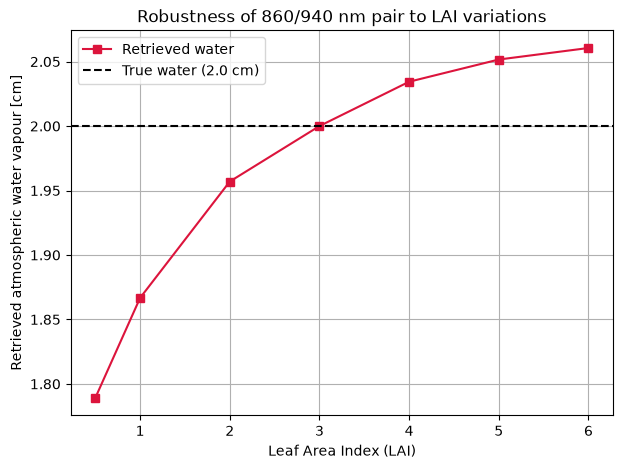

In [48]:

# ---------------------------------------------------------
# ROBUSTNESS TEST FOR 7b: Vary LAI at fixed atmospheric water
# ---------------------------------------------------------
import numpy as np
import matplotlib.pyplot as plt

# 1. Set the fixed atmospheric water we want to retrieve
true_water = 2.0  # cm

# 2. Define a range of LAI values to test
lai_values = [0.5, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0]

# 3. Build the inversion LUT from the previous 7b relationship
# (Assumes water_values and ratios_vnir are already in memory from your code)
invert_lut = np.interp(
    ratios_vnir, 
    water_values, 
    water_values
) # Note: np.interp requires increasing x, so we sort them
sort_idx = np.argsort(ratios_vnir)
lut_ratios = np.array(ratios_vnir)[sort_idx]
lut_water = np.array(water_values)[sort_idx]

retrieved_wv = []

for lai in lai_values:
    # Run PROSAIL and 6S with FIXED water but VARYING LAI
    # (Adapt the run_simulation call to pass your LAI parameter)
    rr, wv_vnir, R_vnir, _, _ = run_simulation(
        water=true_water,
        ozone=ozone_baseline,
        lai=lai  # <-- Add this argument to your run_simulation function
    )
    
    # Interpolate at 865 and 940 nm
    R_selected = np.interp(selected_wavelengths, wv_vnir, R_vnir)
    
    # Calculate the observed ratio
    observed_ratio = R_selected[1] / R_selected[0]
    
    # Retrieve water vapor using the LUT
    retrieved = np.interp(observed_ratio, lut_ratios, lut_water)
    retrieved_wv.append(retrieved)

# 4. Plot the robustness
plt.figure(figsize=(7, 5))
plt.plot(lai_values, retrieved_wv, "s-", color="crimson", label="Retrieved water")
plt.axhline(y=true_water, color="k", linestyle="--", label=f"True water ({true_water} cm)")
plt.xlabel("Leaf Area Index (LAI)")
plt.ylabel("Retrieved atmospheric water vapour [cm]")
plt.title("Robustness of 860/940 nm pair to LAI variations")
plt.grid()
plt.legend()
plt.show()

Analysis

The goal is to retrieve atmospheric column water vapor using a VNIR sensor. Because water vapor absorbs strongly near 940 nm, we cannot simply look at that band in isolation—vegetation also reflects less light there. The standard approach is to ratio the reflectance in an absorption band to a nearby window band (where water vapor is transparent). The exponential attenuation of the absorption band allows us to invert a precomputed 6S lookup table to estimate the column water. However, the ratio still contains the bottom-of-atmosphere (BOA) reflectance of the canopy. Therefore, the algorithm's robustness must be tested by varying biophysical parameters, especially LAI, which alters the NIR reflectance spectrum.

a. The MSI B8A/B9 ratio works as a first-order retrieval because 865 nm and 945 nm are close enough that the atmospheric absorption signal dominates. However, the robustness test reveals a clear failure at low LAI. When LAI is low, the soil background dominates the signal and alters the spectral slope between 865 nm (red edge) and 945 nm (NIR plateau). The algorithm misinterprets this surface-driven change in the ratio as an atmospheric change, underestimating water vapor by up to 0.14 cm. This confirms that the MSI pair requires a surface correction or joint retrieval to be reliable over sparse vegetation.

b. 